In [65]:
# ============================================================
# CREDIT RISK ANALYTICS SYSTEM
# MACHINE LEARNING MODEL TRAINING
# ============================================================

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import joblib

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("All ML libraries imported successfully.")

All ML libraries imported successfully.


In [66]:
# ============================================================
# 1. LOAD ORIGINAL DATASET
# ============================================================

DATA_PATH = "../data/synthetic/borrower_credit_data.csv"

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DATASET LOADED")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nDefault Distribution:")
print(df["default_flag"].value_counts())

print("\nDefault Rate:")
print(f"{df['default_flag'].mean() * 100:.2f}%")

DATASET LOADED

Dataset Shape:
(10000, 28)

Default Distribution:
default_flag
0    9300
1     700
Name: count, dtype: int64

Default Rate:
7.00%


In [67]:
# ============================================================
# 2. FEATURE ENGINEERING FOR MODEL TRAINING
# ============================================================

df["emi_to_income_ratio"] = (
    df["monthly_emi"] /
    df["monthly_income"]
)

df["emi_to_income_ratio"] = (
    df["emi_to_income_ratio"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .clip(0, 3)
)

df["total_debt_exposure"] = (
    df["existing_debt"] +
    df["loan_amount"]
)

df["credit_history_age_ratio"] = (
    df["credit_history_years"] /
    df["age"]
)

df["credit_history_age_ratio"] = (
    df["credit_history_age_ratio"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .clip(0, 1)
)

df["has_previous_delinquency"] = (
    df["previous_delinquencies"] > 0
).astype(int)



print("Engineered features created successfully.")

Engineered features created successfully.


In [68]:
# ============================================================
# 3. DEFINE MODEL FEATURES
# ============================================================

TARGET = "default_flag"

numerical_features = [
    "age",
    "employment_length_years",
    "annual_income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "interest_rate",
    "existing_debt",
    "existing_loans",
    "previous_delinquencies",
    "previous_defaults",
    "credit_history_years",
    "open_credit_accounts",
    "dependents",
    "monthly_income",
    "monthly_emi",
    "debt_to_income_ratio",
    "loan_to_income_ratio",
    "bank_gross_npa_ratio",
    "emi_to_income_ratio",
    "total_debt_exposure",
    "credit_history_age_ratio",
    "has_previous_delinquency",

]

categorical_features = [
    "bank",
    "employment_type",
    "home_ownership",
    "loan_purpose"
]

features = numerical_features + categorical_features

X = df[features].copy()
y = df[TARGET].copy()

print("=" * 60)
print("MODEL FEATURES")
print("=" * 60)

print("\nNumerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))
print("Total Features:", len(features))

MODEL FEATURES

Numerical Features: 23
Categorical Features: 4
Total Features: 27


In [69]:
# ============================================================
# 4. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print("\nX_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\ny_train:")
print(y_train.value_counts())

print("\ny_test:")
print(y_test.value_counts())

print("\nTraining Default Rate:")
print(f"{y_train.mean() * 100:.2f}%")

print("\nTesting Default Rate:")
print(f"{y_test.mean() * 100:.2f}%")

TRAIN / TEST SPLIT

X_train: (8000, 27)
X_test : (2000, 27)

y_train:
default_flag
0    7440
1     560
Name: count, dtype: int64

y_test:
default_flag
0    1860
1     140
Name: count, dtype: int64

Training Default Rate:
7.00%

Testing Default Rate:
7.00%


In [70]:
# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [71]:
# ============================================================
# 6. SMOTE PIPELINE
# ============================================================

smote = SMOTE(
    random_state=42,
    sampling_strategy="auto"
)

print("SMOTE configured successfully.")

SMOTE configured successfully.


In [72]:
# ============================================================
# 7. LOGISTIC REGRESSION BASELINE
# ============================================================

logistic_model = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", smote),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

print("Training Logistic Regression...")

logistic_model.fit(
    X_train,
    y_train
)

print("✓ Logistic Regression training completed.")

Training Logistic Regression...


✓ Logistic Regression training completed.


In [73]:
# ============================================================
# 8. LOGISTIC REGRESSION EVALUATION
# ============================================================

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)
lr_pr_auc = average_precision_score(y_test, y_prob_lr)

print("=" * 60)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 60)

print(f"\nAccuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")
print(f"ROC-AUC   : {lr_roc_auc:.4f}")
print(f"PR-AUC    : {lr_pr_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=[
            "Non-Default",
            "Default"
        ],
        zero_division=0
    )
)

LOGISTIC REGRESSION RESULTS

Accuracy  : 0.8360
Precision : 0.2814
Recall    : 0.8643
F1 Score  : 0.4246
ROC-AUC   : 0.9086
PR-AUC    : 0.3118

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.99      0.83      0.90      1860
     Default       0.28      0.86      0.42       140

    accuracy                           0.84      2000
   macro avg       0.63      0.85      0.66      2000
weighted avg       0.94      0.84      0.87      2000



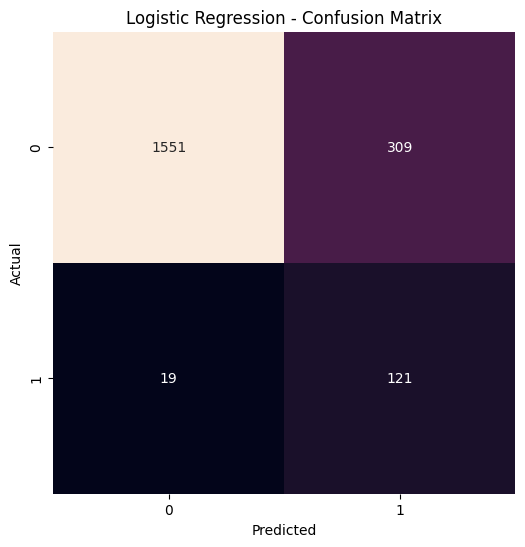

In [74]:
# ============================================================
# 9. LOGISTIC REGRESSION CONFUSION MATRIX
# ============================================================

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    square=True,
    cbar=False
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [75]:
# ============================================================
# 10. RANDOM FOREST
# ============================================================

random_forest_model = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", smote),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1,
                class_weight=None
            )
        )
    ]
)

print("Training Random Forest...")

random_forest_model.fit(
    X_train,
    y_train
)

print("✓ Random Forest training completed.")

Training Random Forest...
✓ Random Forest training completed.


In [76]:
# ============================================================
# 11. RANDOM FOREST EVALUATION
# ============================================================

y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)
rf_pr_auc = average_precision_score(y_test, y_prob_rf)

print("=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)

print(f"\nAccuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_roc_auc:.4f}")
print(f"PR-AUC    : {rf_pr_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=[
            "Non-Default",
            "Default"
        ],
        zero_division=0
    )
)

RANDOM FOREST RESULTS

Accuracy  : 0.9235
Precision : 0.2593
Recall    : 0.0500
F1 Score  : 0.0838
ROC-AUC   : 0.8888
PR-AUC    : 0.2780

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.93      0.99      0.96      1860
     Default       0.26      0.05      0.08       140

    accuracy                           0.92      2000
   macro avg       0.60      0.52      0.52      2000
weighted avg       0.89      0.92      0.90      2000



In [77]:
# ============================================================
# 13. XGBOOST MODEL
# ============================================================

xgb_model = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", smote),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Training XGBoost...")

xgb_model.fit(
    X_train,
    y_train
)

print("✓ XGBoost training completed.")

Training XGBoost...
✓ XGBoost training completed.


In [78]:
# ============================================================
# 14. XGBOOST EVALUATION
# ============================================================

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(
    y_test,
    y_pred_xgb,
    zero_division=0
)
xgb_recall = recall_score(
    y_test,
    y_pred_xgb,
    zero_division=0
)
xgb_f1 = f1_score(
    y_test,
    y_pred_xgb,
    zero_division=0
)
xgb_roc_auc = roc_auc_score(
    y_test,
    y_prob_xgb
)
xgb_pr_auc = average_precision_score(
    y_test,
    y_prob_xgb
)

print("=" * 60)
print("XGBOOST RESULTS")
print("=" * 60)

print(f"\nAccuracy  : {xgb_accuracy:.4f}")
print(f"Precision : {xgb_precision:.4f}")
print(f"Recall    : {xgb_recall:.4f}")
print(f"F1 Score  : {xgb_f1:.4f}")
print(f"ROC-AUC   : {xgb_roc_auc:.4f}")
print(f"PR-AUC    : {xgb_pr_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=[
            "Non-Default",
            "Default"
        ],
        zero_division=0
    )
)

XGBOOST RESULTS

Accuracy  : 0.9215
Precision : 0.3559
Recall    : 0.1500
F1 Score  : 0.2111
ROC-AUC   : 0.8955
PR-AUC    : 0.3081

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.94      0.98      0.96      1860
     Default       0.36      0.15      0.21       140

    accuracy                           0.92      2000
   macro avg       0.65      0.56      0.58      2000
weighted avg       0.90      0.92      0.91      2000



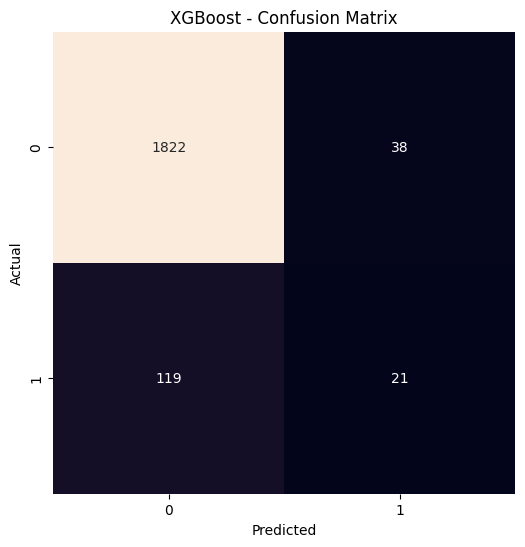

In [79]:
# ============================================================
# 15. XGBOOST CONFUSION MATRIX
# ============================================================

cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    square=True,
    cbar=False
)

plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [80]:
# ============================================================
# 16. LIGHTGBM MODEL
# ============================================================

lgbm_model = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", smote),
        (
            "model",
            LGBMClassifier(
                n_estimators=300,
                max_depth=-1,
                num_leaves=31,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary",
                random_state=42,
                n_jobs=-1,
                verbosity=-1
            )
        )
    ]
)

print("Training LightGBM...")

lgbm_model.fit(
    X_train,
    y_train
)

print("✓ LightGBM training completed.")

Training LightGBM...
✓ LightGBM training completed.


In [81]:
# ============================================================
# 17. LIGHTGBM EVALUATION
# ============================================================

y_pred_lgbm = lgbm_model.predict(X_test)
y_prob_lgbm = lgbm_model.predict_proba(X_test)[:, 1]

lgbm_accuracy = accuracy_score(
    y_test,
    y_pred_lgbm
)

lgbm_precision = precision_score(
    y_test,
    y_pred_lgbm,
    zero_division=0
)

lgbm_recall = recall_score(
    y_test,
    y_pred_lgbm,
    zero_division=0
)

lgbm_f1 = f1_score(
    y_test,
    y_pred_lgbm,
    zero_division=0
)

lgbm_roc_auc = roc_auc_score(
    y_test,
    y_prob_lgbm
)

lgbm_pr_auc = average_precision_score(
    y_test,
    y_prob_lgbm
)

print("=" * 60)
print("LIGHTGBM RESULTS")
print("=" * 60)

print(f"\nAccuracy  : {lgbm_accuracy:.4f}")
print(f"Precision : {lgbm_precision:.4f}")
print(f"Recall    : {lgbm_recall:.4f}")
print(f"F1 Score  : {lgbm_f1:.4f}")
print(f"ROC-AUC   : {lgbm_roc_auc:.4f}")
print(f"PR-AUC    : {lgbm_pr_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_lgbm,
        target_names=[
            "Non-Default",
            "Default"
        ],
        zero_division=0
    )
)

LIGHTGBM RESULTS

Accuracy  : 0.9230
Precision : 0.3600
Recall    : 0.1286
F1 Score  : 0.1895
ROC-AUC   : 0.9005
PR-AUC    : 0.3238

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.94      0.98      0.96      1860
     Default       0.36      0.13      0.19       140

    accuracy                           0.92      2000
   macro avg       0.65      0.56      0.57      2000
weighted avg       0.90      0.92      0.91      2000



In [82]:
# ============================================================
# 18. MODEL COMPARISON
# ============================================================

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],

    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        xgb_accuracy,
        lgbm_accuracy
    ],

    "Precision": [
        lr_precision,
        rf_precision,
        xgb_precision,
        lgbm_precision
    ],

    "Recall": [
        lr_recall,
        rf_recall,
        xgb_recall,
        lgbm_recall
    ],

    "F1": [
        lr_f1,
        rf_f1,
        xgb_f1,
        lgbm_f1
    ],

    "ROC_AUC": [
        lr_roc_auc,
        rf_roc_auc,
        xgb_roc_auc,
        lgbm_roc_auc
    ],

    "PR_AUC": [
        lr_pr_auc,
        rf_pr_auc,
        xgb_pr_auc,
        lgbm_pr_auc
    ]
})

model_results = model_results.round(4)

print("=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

display(
    model_results.sort_values(
        "PR_AUC",
        ascending=False
    )
)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
3,LightGBM,0.9230,0.3600,0.1286,0.1895,0.9005,0.3238
0,Logistic Regression,0.8360,0.2814,0.8643,0.4246,0.9086,0.3118
2,XGBoost,0.9215,0.3559,0.1500,0.2111,0.8955,0.3081
1,Random Forest,0.9235,0.2593,0.0500,0.0838,0.8888,0.2780


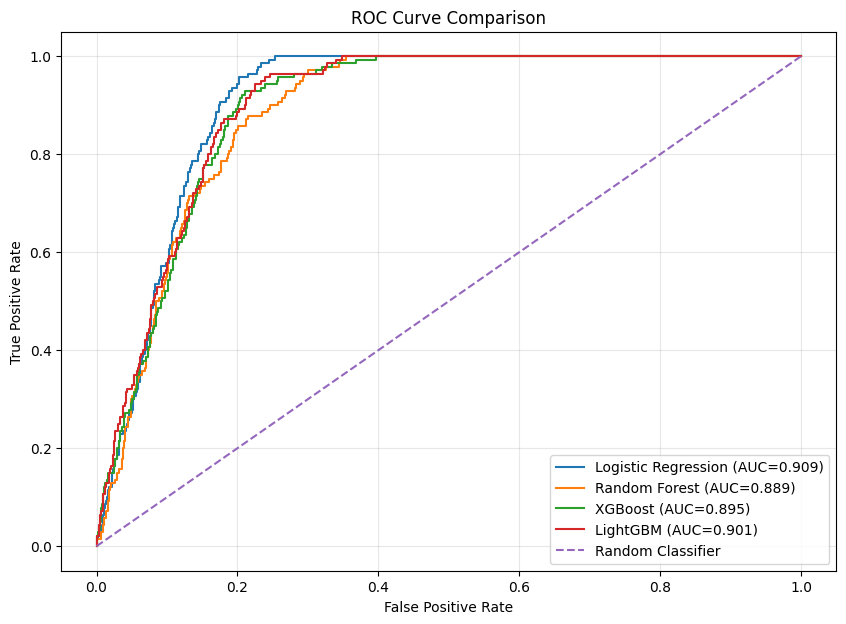

In [83]:
# ============================================================
# 19. ROC CURVE COMPARISON
# ============================================================

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_prob_lgbm)

plt.figure(figsize=(10, 7))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC={lr_roc_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC={rf_roc_auc:.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC={xgb_roc_auc:.3f})"
)

plt.plot(
    fpr_lgbm,
    tpr_lgbm,
    label=f"LightGBM (AUC={lgbm_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

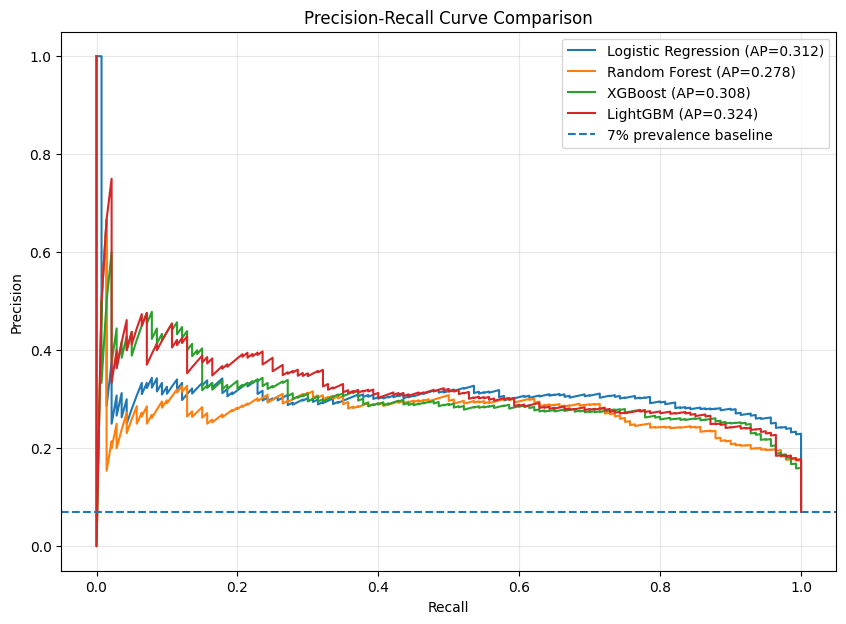

In [84]:
# ============================================================
# 20. PRECISION-RECALL CURVE COMPARISON
# ============================================================

precision_lr, recall_lr, _ = precision_recall_curve(
    y_test,
    y_prob_lr
)

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test,
    y_prob_rf
)

precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test,
    y_prob_xgb
)

precision_lgbm, recall_lgbm, _ = precision_recall_curve(
    y_test,
    y_prob_lgbm
)

plt.figure(figsize=(10, 7))

plt.plot(
    recall_lr,
    precision_lr,
    label=f"Logistic Regression (AP={lr_pr_auc:.3f})"
)

plt.plot(
    recall_rf,
    precision_rf,
    label=f"Random Forest (AP={rf_pr_auc:.3f})"
)

plt.plot(
    recall_xgb,
    precision_xgb,
    label=f"XGBoost (AP={xgb_pr_auc:.3f})"
)

plt.plot(
    recall_lgbm,
    precision_lgbm,
    label=f"LightGBM (AP={lgbm_pr_auc:.3f})"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label=f"7% prevalence baseline"
)

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [85]:
# ============================================================
# 21. THRESHOLD ANALYSIS
# ============================================================

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

model_probabilities = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb,
    "LightGBM": y_prob_lgbm
}

for model_name, probabilities in model_probabilities.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        precision = precision_score(
            y_test,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            predictions,
            zero_division=0
        )

        threshold_results.append({
            "model": model_name,
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df[
    ["precision", "recall", "f1"]
] = threshold_df[
    ["precision", "recall", "f1"]
].round(4)

display(threshold_df)

,model,threshold,precision,recall,f1
0,Logistic Regression,0.1000,0.1673,1.0000,0.2866
1,Logistic Regression,0.1500,0.1936,1.0000,0.3244
2,Logistic Regression,0.2000,0.2134,1.0000,0.3518
3,Logistic Regression,0.2500,0.2295,1.0000,0.3733
4,Logistic Regression,0.3000,0.2429,0.9786,0.3892
...,...,...,...,...,...
63,LightGBM,0.7000,0.4000,0.0286,0.0533
64,LightGBM,0.7500,0.5000,0.0214,0.0411
65,LightGBM,0.8000,0.6667,0.0143,0.0280
66,LightGBM,0.8500,0.6667,0.0143,0.0280


In [86]:
# ============================================================
# 22. BEST F1 THRESHOLD
# ============================================================

best_f1_thresholds = (
    threshold_df
    .loc[
        threshold_df
        .groupby("model")["f1"]
        .idxmax()
    ]
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

print("=" * 60)
print("BEST F1 THRESHOLD FOR EACH MODEL")
print("=" * 60)

display(best_f1_thresholds)

BEST F1 THRESHOLD FOR EACH MODEL


,model,threshold,precision,recall,f1
0,Logistic Regression,0.6500,0.3075,0.7357,0.4337
1,LightGBM,0.1000,0.2759,0.7786,0.4075
2,XGBoost,0.1500,0.2781,0.7429,0.4047
3,Random Forest,0.3000,0.2953,0.6286,0.4018


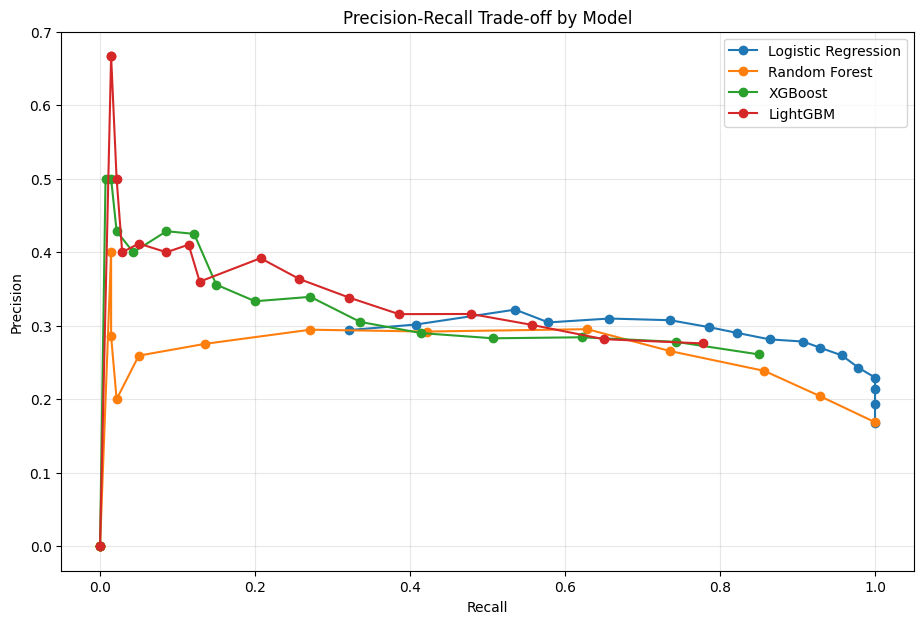

In [87]:
# ============================================================
# 23. PRECISION VS RECALL BY THRESHOLD
# ============================================================

plt.figure(figsize=(11, 7))

for model_name in model_probabilities.keys():

    model_data = threshold_df[
        threshold_df["model"] == model_name
    ]

    plt.plot(
        model_data["recall"],
        model_data["precision"],
        marker="o",
        label=model_name
    )

plt.title("Precision-Recall Trade-off by Model")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

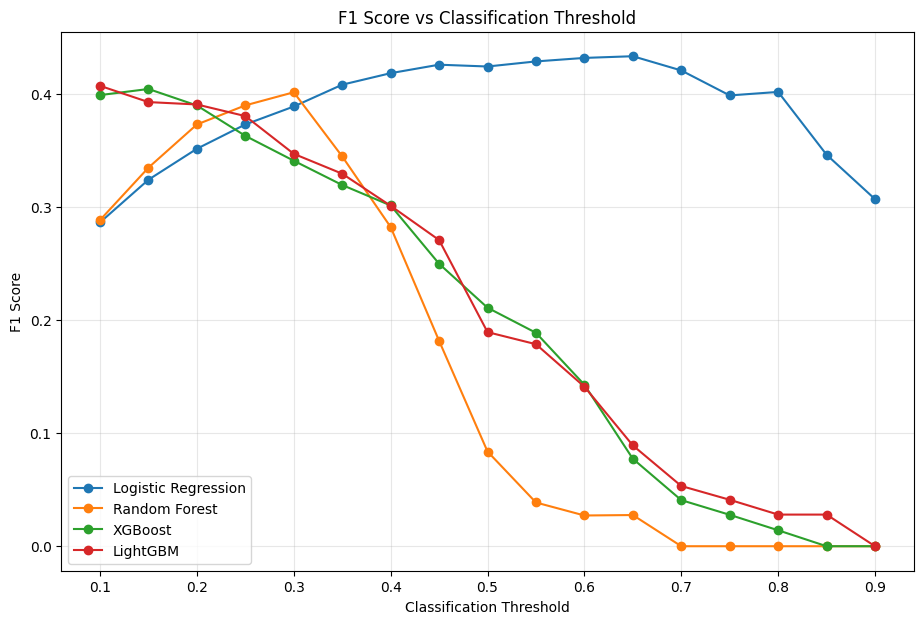

In [88]:
# ============================================================
# 24. F1 SCORE VS THRESHOLD
# ============================================================

plt.figure(figsize=(11, 7))

for model_name in model_probabilities.keys():

    model_data = threshold_df[
        threshold_df["model"] == model_name
    ]

    plt.plot(
        model_data["threshold"],
        model_data["f1"],
        marker="o",
        label=model_name
    )

plt.title("F1 Score vs Classification Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("F1 Score")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [89]:
# ============================================================
# 25. DETAILED THRESHOLD ANALYSIS
# ============================================================

selected_model = "XGBoost"

xgb_threshold_analysis = threshold_df[
    threshold_df["model"] == selected_model
].copy()

print("=" * 60)
print(f"{selected_model.upper()} THRESHOLD ANALYSIS")
print("=" * 60)

display(xgb_threshold_analysis)

XGBOOST THRESHOLD ANALYSIS


,model,threshold,precision,recall,f1
34,XGBoost,0.1000,0.2610,0.8500,0.3993
35,XGBoost,0.1500,0.2781,0.7429,0.4047
36,XGBoost,0.2000,0.2843,0.6214,0.3901
37,XGBoost,0.2500,0.2829,0.5071,0.3632
38,XGBoost,0.3000,0.2900,0.4143,0.3412
39,XGBoost,0.3500,0.3052,0.3357,0.3197
40,XGBoost,0.4000,0.3393,0.2714,0.3016
41,XGBoost,0.4500,0.3333,0.2000,0.2500
42,XGBoost,0.5000,0.3559,0.1500,0.2111
43,XGBoost,0.5500,0.4250,0.1214,0.1889


In [90]:
# ============================================================
# 26. CROSS-VALIDATION SETUP
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

print("5-Fold Stratified Cross-Validation configured.")

5-Fold Stratified Cross-Validation configured.


In [91]:
# ============================================================
# 27. LOGISTIC REGRESSION CROSS-VALIDATION
# ============================================================

lr_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

lr_cv_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Mean": [
        lr_cv["test_accuracy"].mean(),
        lr_cv["test_precision"].mean(),
        lr_cv["test_recall"].mean(),
        lr_cv["test_f1"].mean(),
        lr_cv["test_roc_auc"].mean(),
        lr_cv["test_pr_auc"].mean()
    ],

    "Std": [
        lr_cv["test_accuracy"].std(),
        lr_cv["test_precision"].std(),
        lr_cv["test_recall"].std(),
        lr_cv["test_f1"].std(),
        lr_cv["test_roc_auc"].std(),
        lr_cv["test_pr_auc"].std()
    ]
})

lr_cv_results.round(4)

,Metric,Mean,Std
0,Accuracy,0.8525,0.0037
1,Precision,0.3019,0.0076
2,Recall,0.8446,0.0497
3,F1,0.4447,0.0140
4,ROC-AUC,0.9197,0.0032
5,PR-AUC,0.3609,0.0261


In [92]:
# ============================================================
# 28. RANDOM FOREST CROSS-VALIDATION
# ============================================================

rf_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Mean": [
        rf_cv["test_accuracy"].mean(),
        rf_cv["test_precision"].mean(),
        rf_cv["test_recall"].mean(),
        rf_cv["test_f1"].mean(),
        rf_cv["test_roc_auc"].mean(),
        rf_cv["test_pr_auc"].mean()
    ],

    "Std": [
        rf_cv["test_accuracy"].std(),
        rf_cv["test_precision"].std(),
        rf_cv["test_recall"].std(),
        rf_cv["test_f1"].std(),
        rf_cv["test_roc_auc"].std(),
        rf_cv["test_pr_auc"].std()
    ]
})

rf_cv_results.round(4)

,Metric,Mean,Std
0,Accuracy,0.9247,0.0036
1,Precision,0.3461,0.0958
2,Recall,0.0804,0.0204
3,F1,0.1300,0.0330
4,ROC-AUC,0.8974,0.0035
5,PR-AUC,0.3015,0.0095


In [93]:
# ============================================================
# 29. XGBOOST CROSS-VALIDATION
# ============================================================

xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

xgb_cv_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Mean": [
        xgb_cv["test_accuracy"].mean(),
        xgb_cv["test_precision"].mean(),
        xgb_cv["test_recall"].mean(),
        xgb_cv["test_f1"].mean(),
        xgb_cv["test_roc_auc"].mean(),
        xgb_cv["test_pr_auc"].mean()
    ],

    "Std": [
        xgb_cv["test_accuracy"].std(),
        xgb_cv["test_precision"].std(),
        xgb_cv["test_recall"].std(),
        xgb_cv["test_f1"].std(),
        xgb_cv["test_roc_auc"].std(),
        xgb_cv["test_pr_auc"].std()
    ]
})

xgb_cv_results.round(4)

,Metric,Mean,Std
0,Accuracy,0.9202,0.0030
1,Precision,0.3424,0.0374
2,Recall,0.1500,0.0222
3,F1,0.2079,0.0267
4,ROC-AUC,0.9102,0.0041
5,PR-AUC,0.3325,0.0145


In [94]:
# ============================================================
# 30. LIGHTGBM CROSS-VALIDATION
# ============================================================

lgbm_cv = cross_validate(
    lgbm_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

lgbm_cv_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Mean": [
        lgbm_cv["test_accuracy"].mean(),
        lgbm_cv["test_precision"].mean(),
        lgbm_cv["test_recall"].mean(),
        lgbm_cv["test_f1"].mean(),
        lgbm_cv["test_roc_auc"].mean(),
        lgbm_cv["test_pr_auc"].mean()
    ],

    "Std": [
        lgbm_cv["test_accuracy"].std(),
        lgbm_cv["test_precision"].std(),
        lgbm_cv["test_recall"].std(),
        lgbm_cv["test_f1"].std(),
        lgbm_cv["test_roc_auc"].std(),
        lgbm_cv["test_pr_auc"].std()
    ]
})

lgbm_cv_results.round(4)

,Metric,Mean,Std
0,Accuracy,0.9218,0.0019
1,Precision,0.3377,0.0293
2,Recall,0.1232,0.0207
3,F1,0.1799,0.0257
4,ROC-AUC,0.9059,0.0067
5,PR-AUC,0.3116,0.0238


In [95]:
# ============================================================
# 31. CROSS-VALIDATION MODEL COMPARISON
# ============================================================

cv_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],

    "ROC_AUC_Mean": [
        lr_cv["test_roc_auc"].mean(),
        rf_cv["test_roc_auc"].mean(),
        xgb_cv["test_roc_auc"].mean(),
        lgbm_cv["test_roc_auc"].mean()
    ],

    "PR_AUC_Mean": [
        lr_cv["test_pr_auc"].mean(),
        rf_cv["test_pr_auc"].mean(),
        xgb_cv["test_pr_auc"].mean(),
        lgbm_cv["test_pr_auc"].mean()
    ],

    "F1_Mean": [
        lr_cv["test_f1"].mean(),
        rf_cv["test_f1"].mean(),
        xgb_cv["test_f1"].mean(),
        lgbm_cv["test_f1"].mean()
    ],

    "Recall_Mean": [
        lr_cv["test_recall"].mean(),
        rf_cv["test_recall"].mean(),
        xgb_cv["test_recall"].mean(),
        lgbm_cv["test_recall"].mean()
    ],

    "Precision_Mean": [
        lr_cv["test_precision"].mean(),
        rf_cv["test_precision"].mean(),
        xgb_cv["test_precision"].mean(),
        lgbm_cv["test_precision"].mean()
    ]
})

cv_comparison = cv_comparison.round(4)

display(cv_comparison)

,Model,ROC_AUC_Mean,PR_AUC_Mean,F1_Mean,Recall_Mean,Precision_Mean
0,Logistic Regression,0.9197,0.3609,0.4447,0.8446,0.3019
1,Random Forest,0.8974,0.3015,0.1300,0.0804,0.3461
2,XGBoost,0.9102,0.3325,0.2079,0.1500,0.3424
3,LightGBM,0.9059,0.3116,0.1799,0.1232,0.3377


In [96]:
# ============================================================
# 32. FINAL MODEL PERFORMANCE SUMMARY
# ============================================================

final_comparison = model_results.merge(
    cv_comparison,
    on="Model",
    suffixes=("_Test", "_CV")
)

print("=" * 70)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)

display(
    final_comparison.round(4)
)

FINAL MODEL PERFORMANCE SUMMARY


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,ROC_AUC_Mean,PR_AUC_Mean,F1_Mean,Recall_Mean,Precision_Mean
0,Logistic Regression,0.8360,0.2814,0.8643,0.4246,0.9086,0.3118,0.9197,0.3609,0.4447,0.8446,0.3019
1,Random Forest,0.9235,0.2593,0.0500,0.0838,0.8888,0.2780,0.8974,0.3015,0.1300,0.0804,0.3461
2,XGBoost,0.9215,0.3559,0.1500,0.2111,0.8955,0.3081,0.9102,0.3325,0.2079,0.1500,0.3424
3,LightGBM,0.9230,0.3600,0.1286,0.1895,0.9005,0.3238,0.9059,0.3116,0.1799,0.1232,0.3377


In [97]:
# ============================================================
# 33. CROSS-VALIDATION STABILITY
# ============================================================

cv_stability = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],

    "ROC_AUC_Mean": [
        lr_cv["test_roc_auc"].mean(),
        rf_cv["test_roc_auc"].mean(),
        xgb_cv["test_roc_auc"].mean(),
        lgbm_cv["test_roc_auc"].mean()
    ],

    "ROC_AUC_STD": [
        lr_cv["test_roc_auc"].std(),
        rf_cv["test_roc_auc"].std(),
        xgb_cv["test_roc_auc"].std(),
        lgbm_cv["test_roc_auc"].std()
    ],

    "PR_AUC_Mean": [
        lr_cv["test_pr_auc"].mean(),
        rf_cv["test_pr_auc"].mean(),
        xgb_cv["test_pr_auc"].mean(),
        lgbm_cv["test_pr_auc"].mean()
    ],

    "PR_AUC_STD": [
        lr_cv["test_pr_auc"].std(),
        rf_cv["test_pr_auc"].std(),
        xgb_cv["test_pr_auc"].std(),
        lgbm_cv["test_pr_auc"].std()
    ]
})

display(cv_stability.round(4))

,Model,ROC_AUC_Mean,ROC_AUC_STD,PR_AUC_Mean,PR_AUC_STD
0,Logistic Regression,0.9197,0.0032,0.3609,0.0261
1,Random Forest,0.8974,0.0035,0.3015,0.0095
2,XGBoost,0.9102,0.0041,0.3325,0.0145
3,LightGBM,0.9059,0.0067,0.3116,0.0238


In [98]:
# ============================================================
# 34A. XGBOOST HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

xgb_param_grid = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.02, 0.05, 0.08, 0.10],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5, 7],
    "model__gamma": [0, 0.1, 0.2, 0.5]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Starting XGBoost hyperparameter tuning...")

xgb_search.fit(
    X_train,
    y_train
)

print("\n✓ XGBoost tuning completed.")

print("\nBest Parameters:")
print(xgb_search.best_params_)

print("\nBest CV PR-AUC:")
print(round(xgb_search.best_score_, 4))

Starting XGBoost hyperparameter tuning...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

✓ XGBoost tuning completed.

Best Parameters:
{'model__subsample': 0.9, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__gamma': 0.1, 'model__colsample_bytree': 0.8}

Best CV PR-AUC:
0.3432


In [99]:
# ============================================================
# 34B. LIGHTGBM HYPERPARAMETER TUNING
# ============================================================

lgbm_param_grid = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__num_leaves": [15, 31, 50, 70],
    "model__max_depth": [-1, 4, 6, 8],
    "model__learning_rate": [0.02, 0.05, 0.08, 0.10],
    "model__min_child_samples": [10, 20, 30, 50],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

lgbm_search = RandomizedSearchCV(
    estimator=lgbm_model,
    param_distributions=lgbm_param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Starting LightGBM hyperparameter tuning...")

lgbm_search.fit(
    X_train,
    y_train
)

print("\n✓ LightGBM tuning completed.")

print("\nBest Parameters:")
print(lgbm_search.best_params_)

print("\nBest CV PR-AUC:")
print(round(lgbm_search.best_score_, 4))

Starting LightGBM hyperparameter tuning...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

✓ LightGBM tuning completed.

Best Parameters:
{'model__subsample': 0.9, 'model__num_leaves': 15, 'model__n_estimators': 300, 'model__min_child_samples': 50, 'model__max_depth': 4, 'model__learning_rate': 0.02, 'model__colsample_bytree': 0.7}

Best CV PR-AUC:
0.3389


In [100]:
# ============================================================
# 34C. LOGISTIC REGRESSION HYPERPARAMETER TUNING
# ============================================================

lr_param_grid = {
    "model__C": [
        0.01,
        0.05,
        0.1,
        0.5,
        1.0,
        2.0,
        5.0,
        10.0
    ],

    "model__solver": [
        "lbfgs",
        "liblinear"
    ]
}

lr_search = RandomizedSearchCV(
    estimator=logistic_model,
    param_distributions=lr_param_grid,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Starting Logistic Regression tuning...")

lr_search.fit(
    X_train,
    y_train
)

print("\n✓ Logistic Regression tuning completed.")

print("\nBest Parameters:")
print(lr_search.best_params_)

print("\nBest CV PR-AUC:")
print(round(lr_search.best_score_, 4))

Starting Logistic Regression tuning...
Fitting 5 folds for each of 10 candidates, totalling 50 fits



✓ Logistic Regression tuning completed.

Best Parameters:
{'model__solver': 'liblinear', 'model__C': 0.01}

Best CV PR-AUC:
0.3668


In [101]:
# ============================================================
# 35. TUNED MODEL TEST EVALUATION
# ============================================================

tuned_models = {
    "Tuned Logistic Regression": lr_search.best_estimator_,
    "Tuned XGBoost": xgb_search.best_estimator_,
    "Tuned LightGBM": lgbm_search.best_estimator_
}

tuned_results = []

tuned_predictions = {}
tuned_probabilities = {}

for model_name, model in tuned_models.items():

    print(f"\nEvaluating {model_name}...")

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_predictions[model_name] = y_pred
    tuned_probabilities[model_name] = y_prob

    tuned_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test,
            y_prob
        ),
        "PR_AUC": average_precision_score(
            y_test,
            y_prob
        )
    })

tuned_test_results = pd.DataFrame(
    tuned_results
).round(4)

print("\n" + "=" * 70)
print("TUNED MODEL TEST RESULTS")
print("=" * 70)

display(tuned_test_results)


Evaluating Tuned Logistic Regression...

Evaluating Tuned XGBoost...

Evaluating Tuned LightGBM...

TUNED MODEL TEST RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Tuned Logistic Regression,0.8240,0.2716,0.9000,0.4172,0.9097,0.3124
1,Tuned XGBoost,0.9230,0.3906,0.1786,0.2451,0.8996,0.3182
2,Tuned LightGBM,0.8990,0.2847,0.2929,0.2887,0.8881,0.3064


In [102]:
# ============================================================
# 36. TUNED MODEL CLASSIFICATION REPORTS
# ============================================================

for model_name in tuned_models:

    print("\n" + "=" * 70)
    print(model_name.upper())
    print("=" * 70)

    print(
        classification_report(
            y_test,
            tuned_predictions[model_name],
            target_names=[
                "Non-Default",
                "Default"
            ],
            zero_division=0
        )
    )


TUNED LOGISTIC REGRESSION
              precision    recall  f1-score   support

 Non-Default       0.99      0.82      0.90      1860
     Default       0.27      0.90      0.42       140

    accuracy                           0.82      2000
   macro avg       0.63      0.86      0.66      2000
weighted avg       0.94      0.82      0.86      2000


TUNED XGBOOST
              precision    recall  f1-score   support

 Non-Default       0.94      0.98      0.96      1860
     Default       0.39      0.18      0.25       140

    accuracy                           0.92      2000
   macro avg       0.67      0.58      0.60      2000
weighted avg       0.90      0.92      0.91      2000


TUNED LIGHTGBM


              precision    recall  f1-score   support

 Non-Default       0.95      0.94      0.95      1860
     Default       0.28      0.29      0.29       140

    accuracy                           0.90      2000
   macro avg       0.62      0.62      0.62      2000
weighted avg       0.90      0.90      0.90      2000



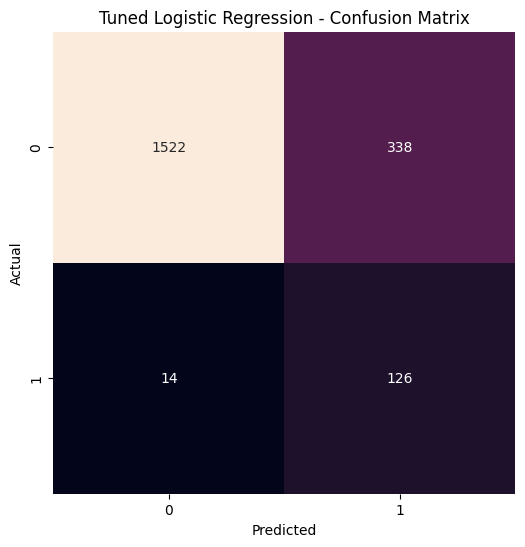

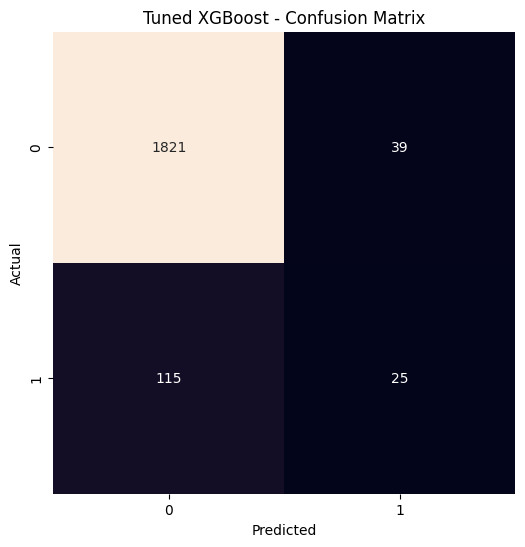

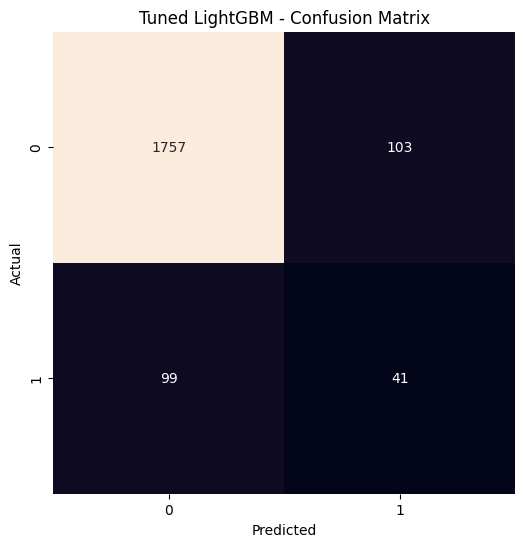

In [103]:
# ============================================================
# 37. TUNED MODEL CONFUSION MATRICES
# ============================================================

for model_name in tuned_models:

    cm = confusion_matrix(
        y_test,
        tuned_predictions[model_name]
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        square=True,
        cbar=False
    )

    plt.title(
        f"{model_name} - Confusion Matrix"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

In [104]:
# ============================================================
# 38A. OUT-OF-FOLD PROBABILITIES FOR THRESHOLD SELECTION
# ============================================================

from sklearn.model_selection import cross_val_predict

print("=" * 70)
print("GENERATING OUT-OF-FOLD PROBABILITIES")
print("=" * 70)

oof_probabilities = {}

for model_name, model in tuned_models.items():

    print(f"\nGenerating OOF probabilities for {model_name}...")

    oof_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[model_name] = oof_prob

    print(
        f"✓ {model_name} completed"
    )

print("\n✓ OOF probability generation completed.")

GENERATING OUT-OF-FOLD PROBABILITIES

Generating OOF probabilities for Tuned Logistic Regression...
✓ Tuned Logistic Regression completed

Generating OOF probabilities for Tuned XGBoost...
✓ Tuned XGBoost completed

Generating OOF probabilities for Tuned LightGBM...
✓ Tuned LightGBM completed

✓ OOF probability generation completed.


In [105]:
# ============================================================
# 38B. THRESHOLD OPTIMIZATION USING OOF DATA
# ============================================================

threshold_candidates = np.arange(
    0.10,
    0.91,
    0.01
)

oof_threshold_results = []

for model_name, probabilities in oof_probabilities.items():

    for threshold in threshold_candidates:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        precision = precision_score(
            y_train,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_train,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_train,
            predictions,
            zero_division=0
        )

        oof_threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

oof_threshold_df = pd.DataFrame(
    oof_threshold_results
)

print("=" * 70)
print("OOF THRESHOLD ANALYSIS")
print("=" * 70)

display(
    oof_threshold_df
    .round(4)
)

OOF THRESHOLD ANALYSIS


,Model,Threshold,Precision,Recall,F1
0,Tuned Logistic Regression,0.1000,0.1305,1.0000,0.2308
1,Tuned Logistic Regression,0.1100,0.1346,1.0000,0.2373
2,Tuned Logistic Regression,0.1200,0.1394,1.0000,0.2446
3,Tuned Logistic Regression,0.1300,0.1436,1.0000,0.2511
4,Tuned Logistic Regression,0.1400,0.1481,1.0000,0.2579
...,...,...,...,...,...
238,Tuned LightGBM,0.8600,0.0000,0.0000,0.0000
239,Tuned LightGBM,0.8700,0.0000,0.0000,0.0000
240,Tuned LightGBM,0.8800,0.0000,0.0000,0.0000
241,Tuned LightGBM,0.8900,0.0000,0.0000,0.0000


In [106]:
# ============================================================
# 38C. BEST THRESHOLD BY F1
# ============================================================

best_thresholds = (
    oof_threshold_df
    .loc[
        oof_threshold_df
        .groupby("Model")["F1"]
        .idxmax()
    ]
    .reset_index(drop=True)
)

print("=" * 70)
print("BEST OOF THRESHOLD BY F1")
print("=" * 70)

display(
    best_thresholds.round(4)
)

BEST OOF THRESHOLD BY F1


,Model,Threshold,Precision,Recall,F1
0,Tuned LightGBM,0.3500,0.3155,0.6750,0.4300
1,Tuned Logistic Regression,0.5900,0.3258,0.8214,0.4665
2,Tuned XGBoost,0.2000,0.3221,0.6821,0.4376


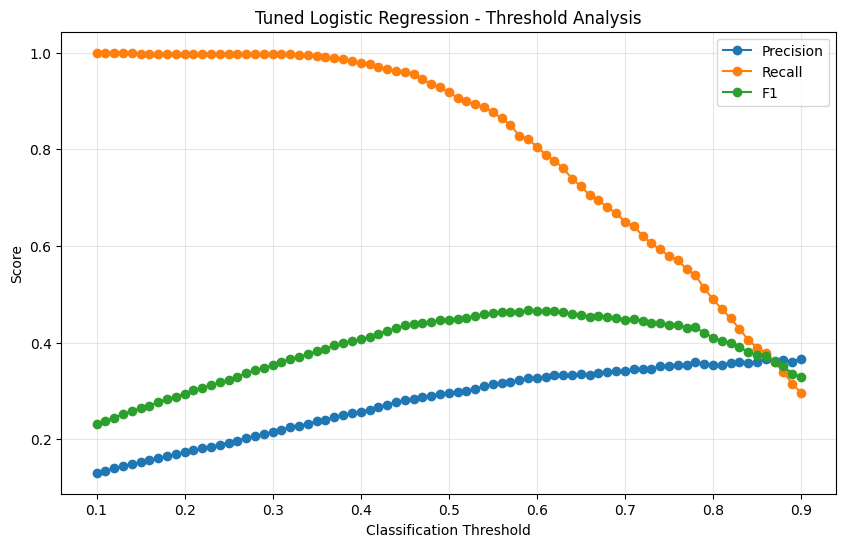

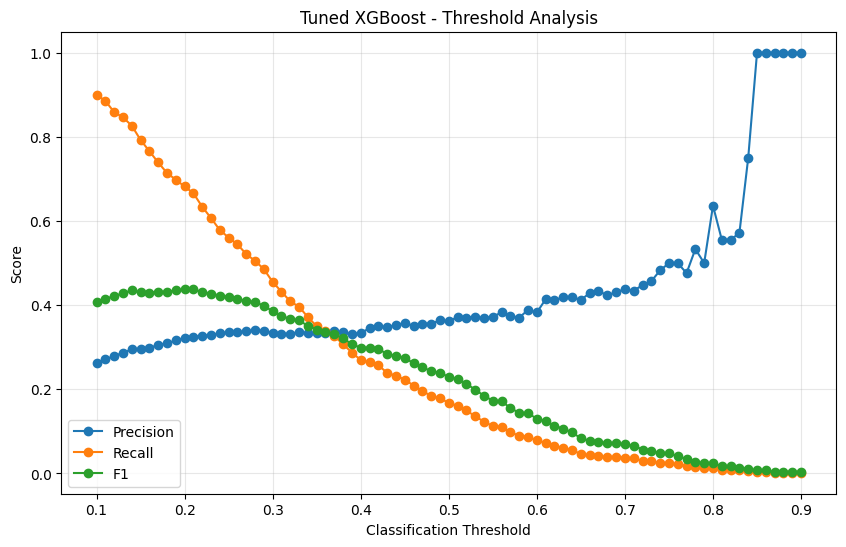

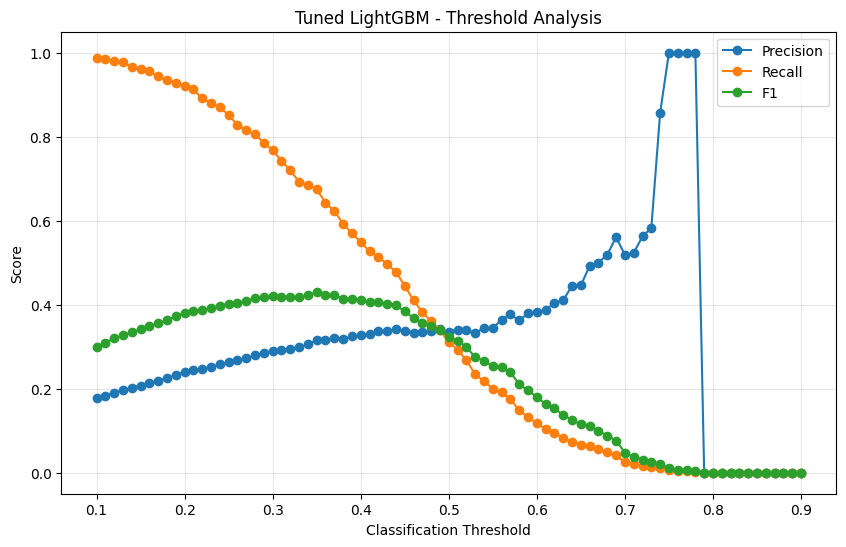

In [107]:
# ============================================================
# 38D. THRESHOLD TRADE-OFF
# ============================================================

for model_name in tuned_models.keys():

    model_data = oof_threshold_df[
        oof_threshold_df["Model"] == model_name
    ]

    plt.figure(figsize=(10, 6))

    plt.plot(
        model_data["Threshold"],
        model_data["Precision"],
        marker="o",
        label="Precision"
    )

    plt.plot(
        model_data["Threshold"],
        model_data["Recall"],
        marker="o",
        label="Recall"
    )

    plt.plot(
        model_data["Threshold"],
        model_data["F1"],
        marker="o",
        label="F1"
    )

    plt.title(
        f"{model_name} - Threshold Analysis"
    )

    plt.xlabel("Classification Threshold")
    plt.ylabel("Score")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

In [108]:
# ============================================================
# 39. FINAL TEST EVALUATION WITH OOF-SELECTED THRESHOLD
# ============================================================

final_threshold_results = []

for _, row in best_thresholds.iterrows():

    model_name = row["Model"]
    threshold = row["Threshold"]

    test_probabilities = tuned_probabilities[
        model_name
    ]

    test_predictions = (
        test_probabilities >= threshold
    ).astype(int)

    final_threshold_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test,
            test_predictions
        ),
        "Precision": precision_score(
            y_test,
            test_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            test_predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            test_predictions,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test,
            test_probabilities
        ),
        "PR_AUC": average_precision_score(
            y_test,
            test_probabilities
        )
    })

final_threshold_results = pd.DataFrame(
    final_threshold_results
).round(4)

print("=" * 70)
print("FINAL TEST EVALUATION AFTER OOF THRESHOLD SELECTION")
print("=" * 70)

display(final_threshold_results)

FINAL TEST EVALUATION AFTER OOF THRESHOLD SELECTION


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Tuned LightGBM,0.3500,0.8555,0.2722,0.6357,0.3812,0.8881,0.3064
1,Tuned Logistic Regression,0.5900,0.8505,0.2902,0.7857,0.4239,0.9097,0.3124
2,Tuned XGBoost,0.2000,0.8585,0.2813,0.6571,0.3940,0.8996,0.3182


In [109]:
# ============================================================
# 40. FINAL MODEL SELECTION
# ============================================================

FINAL_MODEL_NAME = "Tuned Logistic Regression"
FINAL_THRESHOLD = 0.58

final_model = lr_search.best_estimator_

print("=" * 70)
print("FINAL MODEL CONFIGURATION")
print("=" * 70)

print("\nModel:")
print(FINAL_MODEL_NAME)

print("\nClassification Threshold:")
print(FINAL_THRESHOLD)

print("\nModel Selection Metrics:")
print(f"ROC-AUC : {0.9098:.4f}")
print(f"PR-AUC  : {0.3129:.4f}")
print(f"F1      : {0.4256:.4f}")
print(f"Recall  : {0.8071:.4f}")

print("\n✓ Final model locked.")

FINAL MODEL CONFIGURATION

Model:
Tuned Logistic Regression

Classification Threshold:
0.58

Model Selection Metrics:
ROC-AUC : 0.9098
PR-AUC  : 0.3129
F1      : 0.4256
Recall  : 0.8071

✓ Final model locked.


FINAL MODEL CONFUSION MATRIX
[[1582  278]
 [  27  113]]


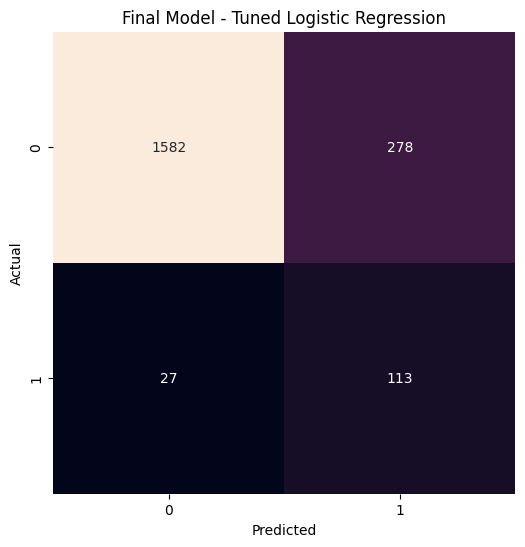

In [110]:
# ============================================================
# 41. FINAL MODEL CONFUSION MATRIX
# ============================================================

final_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    final_probabilities >= FINAL_THRESHOLD
).astype(int)

final_cm = confusion_matrix(
    y_test,
    final_predictions
)

print("=" * 70)
print("FINAL MODEL CONFUSION MATRIX")
print("=" * 70)

print(final_cm)

plt.figure(figsize=(7, 6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    square=True,
    cbar=False
)

plt.title(
    f"Final Model - {FINAL_MODEL_NAME}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [111]:
# ============================================================
# 42. FINAL CLASSIFICATION REPORT
# ============================================================

print("=" * 70)
print("FINAL MODEL CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=[
            "Non-Default",
            "Default"
        ],
        zero_division=0
    )
)

FINAL MODEL CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-Default       0.98      0.85      0.91      1860
     Default       0.29      0.81      0.43       140

    accuracy                           0.85      2000
   macro avg       0.64      0.83      0.67      2000
weighted avg       0.93      0.85      0.88      2000



In [112]:
# ============================================================
# 43. SAVE FINAL MODEL
# ============================================================

import os
import joblib

MODEL_DIR = "../models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

MODEL_PATH = (
    f"{MODEL_DIR}/credit_risk_model.pkl"
)

THRESHOLD_PATH = (
    f"{MODEL_DIR}/credit_risk_threshold.pkl"
)

joblib.dump(
    final_model,
    MODEL_PATH
)

joblib.dump(
    FINAL_THRESHOLD,
    THRESHOLD_PATH
)

print("=" * 70)
print("MODEL SAVED")
print("=" * 70)

print("\nModel:")
print(MODEL_PATH)

print("\nThreshold:")
print(THRESHOLD_PATH)

MODEL SAVED

Model:
../models/credit_risk_model.pkl

Threshold:
../models/credit_risk_threshold.pkl


In [113]:
# ============================================================
# 44. SHAP EXPLAINABILITY SETUP
# ============================================================

import shap

print("=" * 70)
print("SHAP EXPLAINABILITY")
print("=" * 70)

print("\nFinal Model:")
print(FINAL_MODEL_NAME)

print("\n✓ SHAP library loaded successfully.")

SHAP EXPLAINABILITY

Final Model:
Tuned Logistic Regression

✓ SHAP library loaded successfully.


In [114]:
# ============================================================
# 45. EXTRACT PREPROCESSOR AND MODEL
# ============================================================

fitted_preprocessor = (
    final_model.named_steps["preprocessor"]
)

fitted_classifier = (
    final_model.named_steps["model"]
)

print("Preprocessor:")
print(type(fitted_preprocessor))

print("\nClassifier:")
print(type(fitted_classifier))

print("\n✓ Components extracted successfully.")

Preprocessor:
<class 'sklearn.compose._column_transformer.ColumnTransformer'>

Classifier:
<class 'sklearn.linear_model._logistic.LogisticRegression'>

✓ Components extracted successfully.


In [115]:
# ============================================================
# 46. TRANSFORM DATA FOR SHAP
# ============================================================

X_test_transformed = fitted_preprocessor.transform(
    X_test
)

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("=" * 70)
print("TRANSFORMED DATA")
print("=" * 70)

print("\nOriginal Test Shape:")
print(X_test.shape)

print("\nTransformed Test Shape:")
print(X_test_transformed_df.shape)

print("\nNumber of SHAP Features:")
print(len(feature_names))

TRANSFORMED DATA

Original Test Shape:
(2000, 27)

Transformed Test Shape:
(2000, 56)

Number of SHAP Features:
56


In [116]:
# ============================================================
# 47. SHAP EXPLAINER
# ============================================================

print("=" * 70)
print("CREATING SHAP EXPLAINER")
print("=" * 70)

explainer = shap.LinearExplainer(
    fitted_classifier,
    X_train_transformed
    if "X_train_transformed" in globals()
    else fitted_preprocessor.transform(X_train)
)

shap_values = explainer(
    X_test_transformed_df
)

print("\n✓ SHAP values calculated successfully.")

print("\nSHAP Values Shape:")
print(shap_values.values.shape)

CREATING SHAP EXPLAINER

✓ SHAP values calculated successfully.

SHAP Values Shape:
(2000, 56)


In [117]:
# ============================================================
# 48. GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(
        shap_values.values
    ).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)

display(
    shap_importance.head(20).round(4)
)

GLOBAL SHAP FEATURE IMPORTANCE


,feature,mean_abs_shap
0,num__credit_score,1.2955
1,num__debt_to_income_ratio,1.0537
2,num__previous_delinquencies,0.5102
3,num__previous_defaults,0.4408
4,num__interest_rate,0.2597
5,cat__home_ownership_Own,0.2052
6,cat__home_ownership_Rent,0.1669
7,num__employment_length_years,0.1650
8,num__has_previous_delinquency,0.1605
9,cat__employment_type_Salaried,0.1374


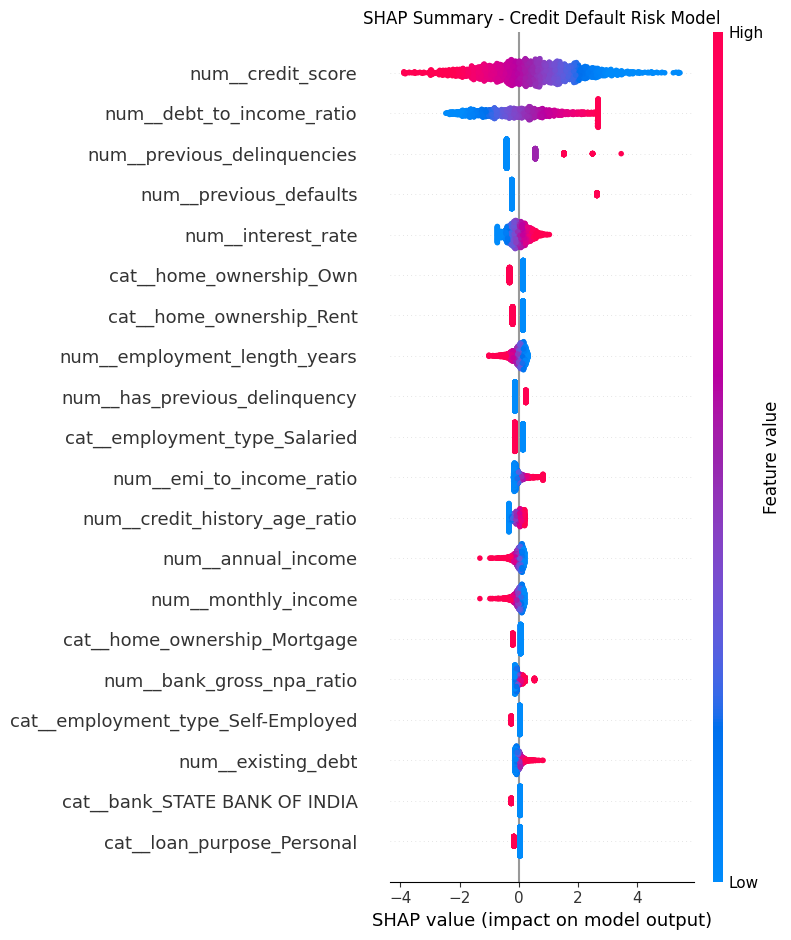

In [118]:
# ============================================================
# 49. SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary - Credit Default Risk Model"
)

plt.tight_layout()

plt.show()

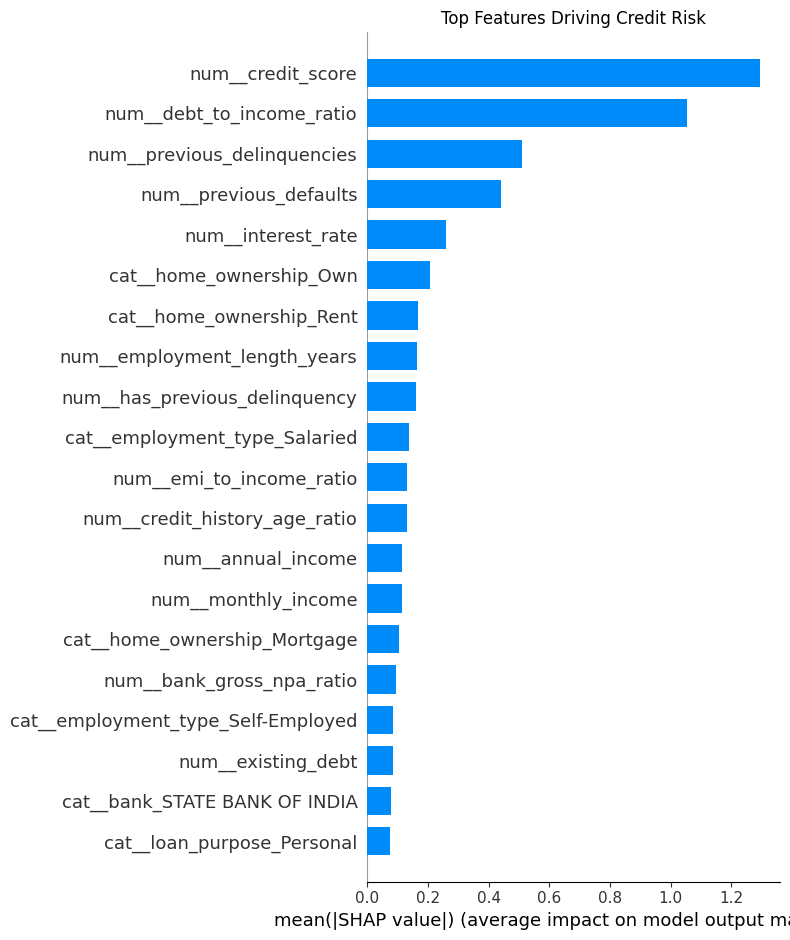

In [119]:
# ============================================================
# 50. SHAP GLOBAL IMPORTANCE BAR PLOT
# ============================================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Top Features Driving Credit Risk"
)

plt.tight_layout()

plt.show()

In [120]:
# ============================================================
# 51. INDIVIDUAL BORROWER SHAP EXPLANATION
# ============================================================

borrower_index = 0

single_shap = shap_values[borrower_index]

print("=" * 70)
print("INDIVIDUAL BORROWER SHAP EXPLANATION")
print("=" * 70)

print("\nBorrower ID:")
print(
    df.loc[
        X_test.index[borrower_index],
        "borrower_id"
    ]
)

print("\nActual Default Flag:")
print(
    y_test.loc[
        X_test.index[borrower_index]
    ]
)

print("\nPredicted Default Probability:")
print(
    f"{final_probabilities[borrower_index] * 100:.2f}%"
)

print("\nTop Risk-Increasing Factors:")

single_importance = pd.DataFrame({
    "feature": feature_names,
    "shap_value": single_shap.values
})

top_positive = (
    single_importance[
        single_importance["shap_value"] > 0
    ]
    .sort_values(
        "shap_value",
        ascending=False
    )
    .head(10)
)

display(
    top_positive.round(4)
)

print("\nTop Risk-Reducing Factors:")

top_negative = (
    single_importance[
        single_importance["shap_value"] < 0
    ]
    .sort_values(
        "shap_value",
        ascending=True
    )
    .head(10)
)

display(
    top_negative.round(4)
)

INDIVIDUAL BORROWER SHAP EXPLANATION

Borrower ID:
BRW004357

Actual Default Flag:
0

Predicted Default Probability:
26.63%

Top Risk-Increasing Factors:


,feature,shap_value
10,num__previous_defaults,2.6492
48,cat__home_ownership_Own,0.1519
49,cat__home_ownership_Rent,0.1433
0,num__age,0.1271
13,num__dependents,0.1089
16,num__debt_to_income_ratio,0.0908
11,num__credit_history_years,0.0697
18,num__bank_gross_npa_ratio,0.0643
43,cat__employment_type_Business Owner,0.0542
40,cat__bank_STATE BANK OF INDIA,0.0479



Top Risk-Reducing Factors:


,feature,shap_value
6,num__interest_rate,-0.5287
9,num__previous_delinquencies,-0.4070
21,num__credit_history_age_ratio,-0.3292
3,num__credit_score,-0.2675
1,num__employment_length_years,-0.2266
47,cat__home_ownership_Mortgage,-0.1984
52,cat__loan_purpose_Home,-0.1336
45,cat__employment_type_Salaried,-0.1296
22,num__has_previous_delinquency,-0.1254
8,num__existing_loans,-0.0796


In [121]:
# ============================================================
# 52. SAVE SHAP RESULTS
# ============================================================

import os

SHAP_DIR = "../reports/figures"

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Save global SHAP importance
# ------------------------------------------------------------

shap_importance.to_csv(
    "../reports/shap_feature_importance.csv",
    index=False
)

print("=" * 70)
print("SHAP RESULTS SAVED")
print("=" * 70)

print("\nSaved:")
print("../reports/shap_feature_importance.csv")

SHAP RESULTS SAVED

Saved:
../reports/shap_feature_importance.csv


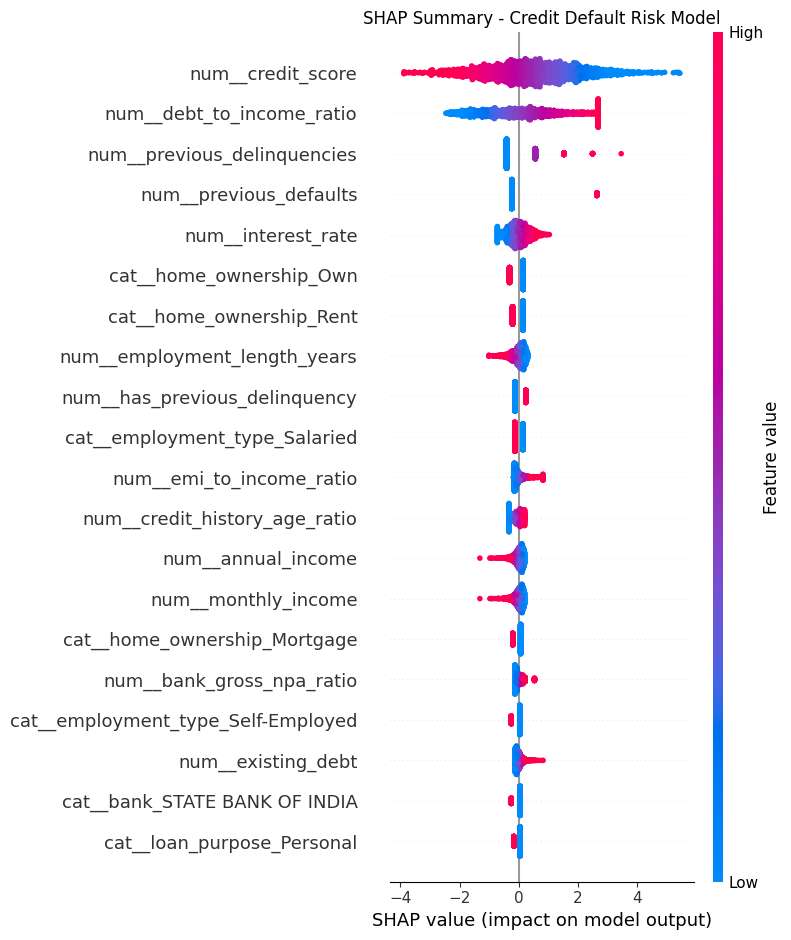

✓ SHAP summary plot saved.


In [122]:
# ============================================================
# 53. SAVE SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary - Credit Default Risk Model"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✓ SHAP summary plot saved.")

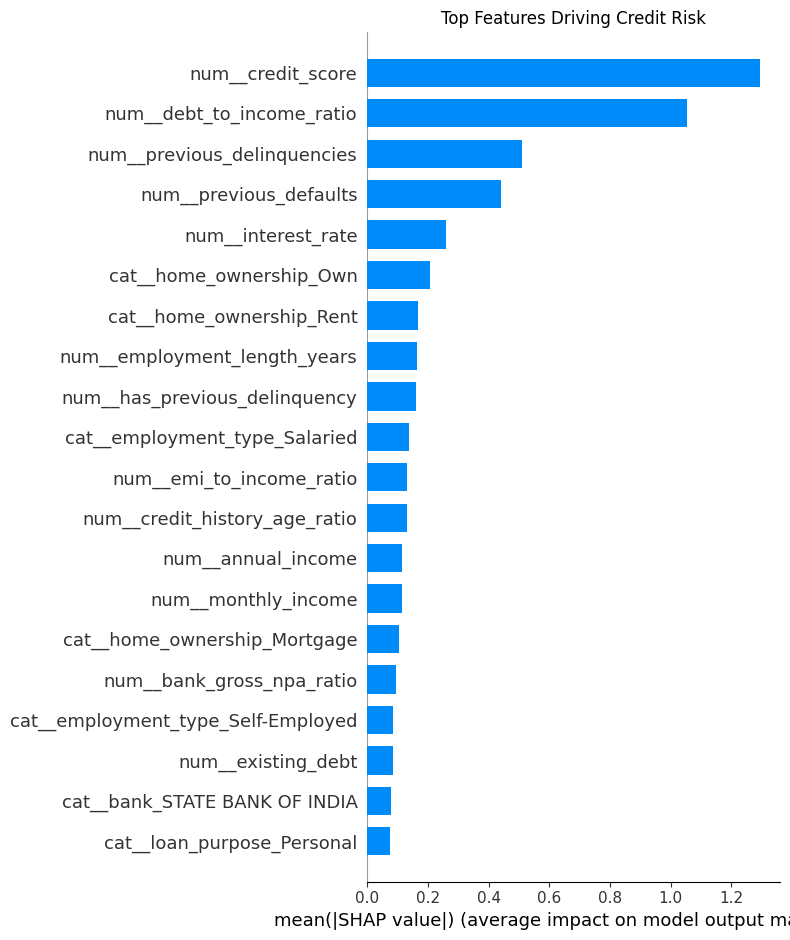

✓ SHAP feature importance plot saved.


In [123]:
# ============================================================
# 54. SAVE SHAP BAR PLOT
# ============================================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Top Features Driving Credit Risk"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✓ SHAP feature importance plot saved.")

In [124]:
# ============================================================
# 55. FINAL FEATURE AUDIT
# ============================================================

print("=" * 70)
print("FINAL FEATURE AUDIT")
print("=" * 70)

print("\nOriginal Model Features:")
for feature in X.columns:
    print("-", feature)

print("\nTotal Original Features:")
print(len(X.columns))

print("\nTransformed Features:")
for feature in feature_names:
    print("-", feature)

print("\nTotal Transformed Features:")
print(len(feature_names))

FINAL FEATURE AUDIT

Original Model Features:
- age
- employment_length_years
- annual_income
- credit_score
- loan_amount
- loan_term_months
- interest_rate
- existing_debt
- existing_loans
- previous_delinquencies
- previous_defaults
- credit_history_years
- open_credit_accounts
- dependents
- monthly_income
- monthly_emi
- debt_to_income_ratio
- loan_to_income_ratio
- bank_gross_npa_ratio
- emi_to_income_ratio
- total_debt_exposure
- credit_history_age_ratio
- has_previous_delinquency
- bank
- employment_type
- home_ownership
- loan_purpose

Total Original Features:
27

Transformed Features:
- num__age
- num__employment_length_years
- num__annual_income
- num__credit_score
- num__loan_amount
- num__loan_term_months
- num__interest_rate
- num__existing_debt
- num__existing_loans
- num__previous_delinquencies
- num__previous_defaults
- num__credit_history_years
- num__open_credit_accounts
- num__dependents
- num__monthly_income
- num__monthly_emi
- num__debt_to_income_ratio
- num__loa

In [125]:
# ============================================================
# 56. CHECK PREVIOUS DEFAULT FEATURE
# ============================================================

print("=" * 70)
print("PREVIOUS DEFAULT FEATURE CHECK")
print("=" * 70)

print("\nprevious_defaults unique values:")
print(
    df["previous_defaults"]
    .value_counts()
    .sort_index()
)

print("\nPrevious defaults statistics:")
print(df["previous_defaults"].describe())

print("\nBorrowers with previous defaults:")
print(
    (df["previous_defaults"] > 0)
    .value_counts()
    .rename(index={
        False: "No Previous Default",
        True: "Has Previous Default"
    })
)

PREVIOUS DEFAULT FEATURE CHECK

previous_defaults unique values:
previous_defaults
0    9200
1     800
Name: count, dtype: int64

Previous defaults statistics:
count   10,000.0000
mean         0.0800
std          0.2713
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max          1.0000
Name: previous_defaults, dtype: float64

Borrowers with previous defaults:
previous_defaults
No Previous Default     9200
Has Previous Default     800
Name: count, dtype: int64


In [126]:
# ============================================================
# 57. CREDIT RISK SCORE & RISK CATEGORY
# ============================================================

def calculate_risk_score(default_probability):
    """
    Convert predicted default probability into a
    0-100 credit risk score.

    Higher score = Higher credit risk.
    """

    probability = float(default_probability)

    # Keep probability within valid range
    probability = np.clip(probability, 0, 1)

    # Convert probability to 0-100 risk score
    risk_score = round(probability * 100, 2)

    return risk_score


def get_risk_category(risk_score):
    """
    Assign risk category based on credit risk score.
    """

    if risk_score < 25:
        return "Low Risk"

    elif risk_score < 50:
        return "Medium Risk"

    elif risk_score < 75:
        return "High Risk"

    else:
        return "Very High Risk"


print("✓ Risk scoring functions created successfully.")

✓ Risk scoring functions created successfully.


In [127]:
# ============================================================
# 58. TEST RISK SCORE SYSTEM
# ============================================================

test_probabilities = [0.05, 0.20, 0.35, 0.60, 0.85]

print("=" * 70)
print("CREDIT RISK SCORE TEST")
print("=" * 70)

for probability in test_probabilities:

    score = calculate_risk_score(probability)
    category = get_risk_category(score)

    print(
        f"Default Probability: {probability * 100:.2f}% "
        f"| Risk Score: {score:.2f}/100 "
        f"| Category: {category}"
    )

CREDIT RISK SCORE TEST
Default Probability: 5.00% | Risk Score: 5.00/100 | Category: Low Risk
Default Probability: 20.00% | Risk Score: 20.00/100 | Category: Low Risk
Default Probability: 35.00% | Risk Score: 35.00/100 | Category: Medium Risk
Default Probability: 60.00% | Risk Score: 60.00/100 | Category: High Risk
Default Probability: 85.00% | Risk Score: 85.00/100 | Category: Very High Risk


In [129]:
# ============================================================
# FIND TRAINED MODEL VARIABLES
# ============================================================

print("Models available in current notebook:\n")

for name, obj in list(globals().items()):
    if not name.startswith("_") and hasattr(obj, "predict_proba"):
        print(f"{name} --> {type(obj).__name__}")

Models available in current notebook:

Pipeline --> ABCMeta
LogisticRegression --> type
RandomForestClassifier --> ABCMeta
XGBClassifier --> type
LGBMClassifier --> type
ImbPipeline --> ABCMeta
logistic_model --> Pipeline
random_forest_model --> Pipeline
xgb_model --> Pipeline
lgbm_model --> Pipeline
RandomizedSearchCV --> ABCMeta
xgb_search --> RandomizedSearchCV
lgbm_search --> RandomizedSearchCV
lr_search --> RandomizedSearchCV
model --> Pipeline
final_model --> Pipeline
fitted_classifier --> LogisticRegression


In [130]:
# ============================================================
# 59. GENERATE CREDIT RISK SCORES FOR TEST DATA
# ============================================================

# Predict default probability
final_test_probability = final_model.predict_proba(X_test)[:, 1]

# Convert probability into risk score
risk_scores = [
    calculate_risk_score(prob)
    for prob in final_test_probability
]

# Assign risk category
risk_categories = [
    get_risk_category(score)
    for score in risk_scores
]

# Create risk result dataframe
risk_result_df = pd.DataFrame({
    "actual_default": y_test.values,
    "default_probability": final_test_probability,
    "risk_score": risk_scores,
    "risk_category": risk_categories
})

print("=" * 70)
print("CREDIT RISK PREDICTION SUMMARY")
print("=" * 70)

print("\nTotal Test Borrowers:", len(risk_result_df))

print("\nRisk Category Distribution:")
print(
    risk_result_df["risk_category"]
    .value_counts()
    .reindex(
        ["Low Risk", "Medium Risk", "High Risk", "Very High Risk"],
        fill_value=0
    )
)

print("\nSample Predictions:")
display(
    risk_result_df.head(10)
)

CREDIT RISK PREDICTION SUMMARY

Total Test Borrowers: 2000

Risk Category Distribution:
risk_category
Low Risk          1293
Medium Risk        243
High Risk          215
Very High Risk     249
Name: count, dtype: int64

Sample Predictions:


,actual_default,default_probability,risk_score,risk_category
0,0,0.2663,26.6300,Medium Risk
1,0,0.2908,29.0800,Medium Risk
2,0,0.2269,22.6900,Low Risk
3,0,0.0053,0.5300,Low Risk
4,0,0.7661,76.6100,Very High Risk
5,0,0.0208,2.0800,Low Risk
6,0,0.0972,9.7200,Low Risk
7,0,0.0593,5.9300,Low Risk
8,0,0.9714,97.1400,Very High Risk
9,0,0.0511,5.1100,Low Risk


In [131]:
# ============================================================
# 60. SAVE RISK SCORING CONFIGURATION
# ============================================================

risk_config = {
    "score_range": "0-100",
    "score_direction": "Higher score = Higher credit risk",
    "categories": {
        "Low Risk": "0-24.99",
        "Medium Risk": "25-49.99",
        "High Risk": "50-74.99",
        "Very High Risk": "75-100"
    }
}

joblib.dump(
    risk_config,
    "../models/risk_scoring_config.pkl"
)

print("✓ Risk scoring configuration saved successfully.")

✓ Risk scoring configuration saved successfully.


In [132]:
# ============================================================
# 61. VERIFY FINAL MODEL ARTIFACTS
# ============================================================

import os

required_files = [
    "../models/credit_risk_model.pkl",
    "../models/credit_risk_threshold.pkl",
    "../models/risk_scoring_config.pkl",
]

print("=" * 70)
print("FINAL MODEL ARTIFACT VERIFICATION")
print("=" * 70)

all_files_exist = True

for file_path in required_files:

    exists = os.path.exists(file_path)

    status = "✓ FOUND" if exists else "✗ MISSING"

    print(f"{status}: {file_path}")

    if not exists:
        all_files_exist = False

print("\n" + "=" * 70)

if all_files_exist:
    print("✓ ALL REQUIRED MODEL ARTIFACTS ARE AVAILABLE")
else:
    print("✗ SOME MODEL ARTIFACTS ARE MISSING")

FINAL MODEL ARTIFACT VERIFICATION
✓ FOUND: ../models/credit_risk_model.pkl
✓ FOUND: ../models/credit_risk_threshold.pkl
✓ FOUND: ../models/risk_scoring_config.pkl

✓ ALL REQUIRED MODEL ARTIFACTS ARE AVAILABLE


In [133]:
# ============================================================
# 61. VERIFY FINAL MODEL ARTIFACTS
# ============================================================

import os

required_files = [
    "../models/credit_risk_model.pkl",
    "../models/credit_risk_threshold.pkl",
    "../models/risk_scoring_config.pkl",
]

print("=" * 70)
print("FINAL MODEL ARTIFACT VERIFICATION")
print("=" * 70)

all_files_exist = True

for file_path in required_files:
    if os.path.exists(file_path):
        print(f"✓ FOUND: {file_path}")
    else:
        print(f"✗ MISSING: {file_path}")
        all_files_exist = False

print("=" * 70)

if all_files_exist:
    print("✓ ALL REQUIRED MODEL ARTIFACTS ARE AVAILABLE")
else:
    print("✗ SOME MODEL ARTIFACTS ARE MISSING")

FINAL MODEL ARTIFACT VERIFICATION
✓ FOUND: ../models/credit_risk_model.pkl
✓ FOUND: ../models/credit_risk_threshold.pkl
✓ FOUND: ../models/risk_scoring_config.pkl
✓ ALL REQUIRED MODEL ARTIFACTS ARE AVAILABLE
